# A large dataset: wine quality

Download and explore **1,599 red wines with 12 measured columns**, then export every observation in a landscape PDF appendix. Tables use Tabloom's plain black-and-white defaults; the charts demonstrate color-encoded scatter plots, overlaid distributions, and grouped box plots.

Run in an environment with `tabloom[example]` installed. The first run needs internet access; subsequent runs reuse `data/winequality-red.csv`. Generated PDFs and PNGs go into `outputs/` beneath the notebook's working directory. Downloaded data and generated notebook outputs are ignored by Git when run from `notebooks/`.

**Source and attribution:** Cortez, P., Cerdeira, A., Almeida, F., Matos, T., and Reis, J. (2009), [Wine Quality, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/186/wine+quality), [DOI: 10.24432/C56S3T](https://doi.org/10.24432/C56S3T). The dataset is licensed under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). We use the red-wine CSV; these are observational measurements, not causal evidence.

In [1]:
from pathlib import Path
from urllib.request import urlopen

import pandas as pd
import tabloom
from tabloom import Chart, Report, Table

print(tabloom.__version__)

0.1.0


## Download once and load through Table

The source CSV uses semicolons. The shape check makes an unexpected download or changed dataset visible before analysis. No external dataset package is needed.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
csv_path = Path("data") / "winequality-red.csv"
csv_path.parent.mkdir(parents=True, exist_ok=True)
if not csv_path.exists():
    with urlopen(DATA_URL, timeout=30) as response:
        csv_path.write_bytes(response.read())
    print("Downloaded the UCI red-wine CSV.")
else:
    print("Using the cached CSV.")

wines = Table.from_csv(csv_path, sep=";")
assert wines.df.shape == (1599, 12)
assert not wines.df.isna().any().any()
print(f"Loaded {len(wines.df):,} observations and {len(wines.df.columns)} columns.")

Downloaded the UCI red-wine CSV.
Loaded 1,599 observations and 12 columns.


## Preview a wide, plain table

All 12 source columns are kept. Short multiline headers make them easier to read, and a separate row number identifies observations in the appendix. The display DataFrame does not alter the original data in `wines.df`. Typography and dimensions control readability; no color styling or theme override is supplied.

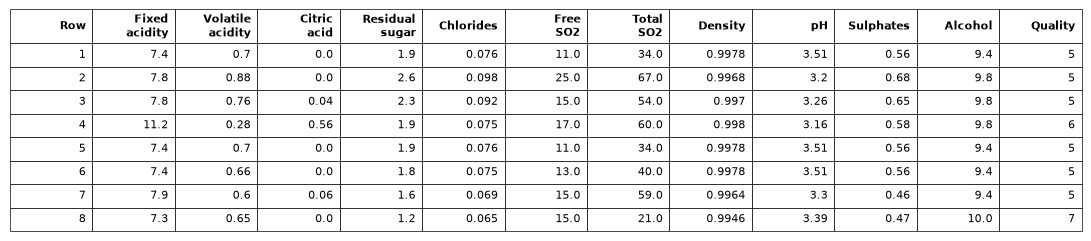

In [3]:
headers = {
    "fixed acidity": "Fixed\nacidity", "volatile acidity": "Volatile\nacidity",
    "citric acid": "Citric\nacid", "residual sugar": "Residual\nsugar",
    "chlorides": "Chlorides", "free sulfur dioxide": "Free\nSO2",
    "total sulfur dioxide": "Total\nSO2", "density": "Density",
    "pH": "pH", "sulphates": "Sulphates", "alcohol": "Alcohol", "quality": "Quality",
}
display_data = wines.df.rename(columns=headers).copy()
display_data.insert(0, "Row", range(1, len(display_data) + 1))
preview = Table(
    display_data.head(8),
    style={"font_size": 8, "column_widths": [1] * len(display_data.columns)},
    figsize=(10.8, 2.3),
)
preview.show()

## Summarize with pandas, present with Tabloom

The grouped table includes all quality levels. Values are rounded only for this summary; the data appendix retains the original measurements.

In [4]:
summary_data = (
    wines.df.groupby("quality")
    .agg(
        Samples=("quality", "size"),
        Alcohol=("alcohol", "mean"),
        Volatile_acidity=("volatile acidity", "mean"),
        Sulphates=("sulphates", "mean"),
    )
    .round(3)
    .reset_index()
    .rename(columns={"quality": "Quality", "Volatile_acidity": "Mean volatile acidity", "Alcohol": "Mean alcohol", "Sulphates": "Mean sulphates"})
)
summary_table = Table(summary_data, style={"font_size": 9}, figsize=(10.8, 2.5))
print(summary_data.to_string(index=False))

 Quality  Samples  Mean alcohol  Mean volatile acidity  Mean sulphates
       3       10         9.955                  0.885           0.570
       4       53        10.265                  0.694           0.596
       5      681         9.900                  0.577           0.621
       6      638        10.630                  0.497           0.675
       7      199        11.466                  0.404           0.741
       8       18        12.094                  0.423           0.768


## Scatter: color, a colorbar, and an association line

Each point is a wine. Color encodes its quality score. A simple least-squares line illustrates the association between alcohol and volatile acidity; it is descriptive, not a predictive model. Use the exposed Figure/Axes to add a colorbar and overlay.

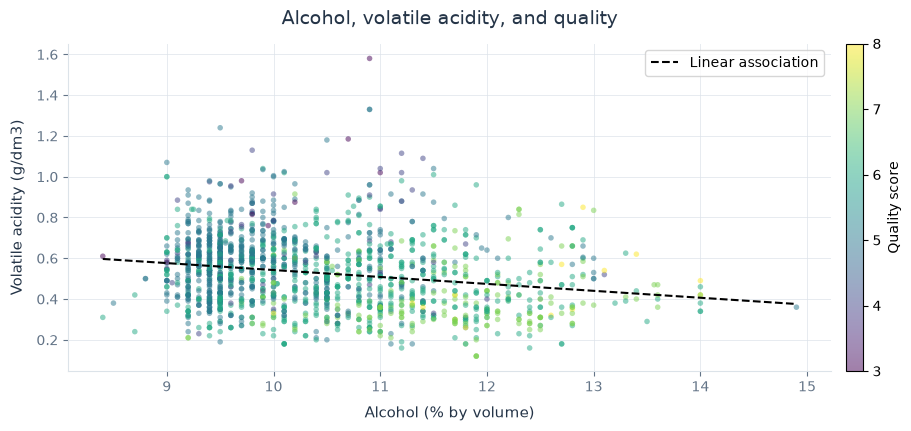

In [5]:
scatter = Chart.scatter(
    data=wines, x="alcohol", y="volatile acidity",
    c=wines.df["quality"], cmap="viridis", vmin=3, vmax=8,
    s=16, alpha=0.5, edgecolors="none",
    title="Alcohol, volatile acidity, and quality",
    xlabel="Alcohol (% by volume)", ylabel="Volatile acidity (g/dm3)",
    figsize=(9, 4.2),
)
colorbar = scatter.fig.colorbar(scatter.ax.collections[0], ax=scatter.ax, pad=0.02)
colorbar.set_label("Quality score")
slope = wines.df["alcohol"].cov(wines.df["volatile acidity"]) / wines.df["alcohol"].var()
intercept = wines.df["volatile acidity"].mean() - slope * wines.df["alcohol"].mean()
x_range = [wines.df["alcohol"].min(), wines.df["alcohol"].max()]
scatter.ax.plot(
    x_range, [intercept + slope * value for value in x_range],
    color="black", linestyle="--", linewidth=1.5, label="Linear association",
)
scatter.ax.legend(loc="upper right")
scatter.show()

## Histogram: compare two distributions

Two overlaid, normalized histograms compare alcohol measurements for quality scores at most 5 versus at least 6. Density normalization makes distributions comparable even when their group sizes differ.

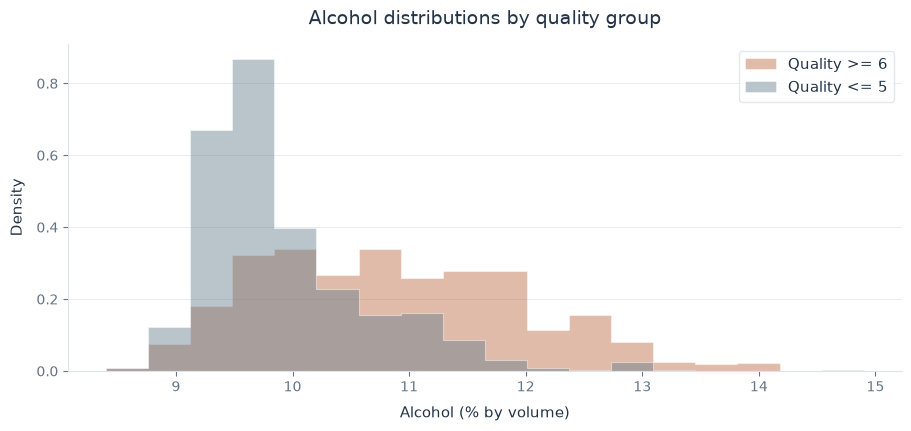

In [6]:
histogram = Chart.hist(
    [wines.df.loc[wines.df["quality"] <= 5, "alcohol"],
     wines.df.loc[wines.df["quality"] >= 6, "alcohol"]],
    bins=18, density=True, histtype="stepfilled", alpha=0.45,
    color=["#647c8c", "#bd6844"], label=["Quality <= 5", "Quality >= 6"],
    title="Alcohol distributions by quality group",
    xlabel="Alcohol (% by volume)", ylabel="Density",
    figsize=(9, 4.2),
)
histogram.show()

## Box plots: grouped distributions and sample counts

Whiskers span the 5th to 95th percentiles; points beyond them remain visible. White diamonds mark means. The labels include sample counts, so sparse quality groups are apparent.

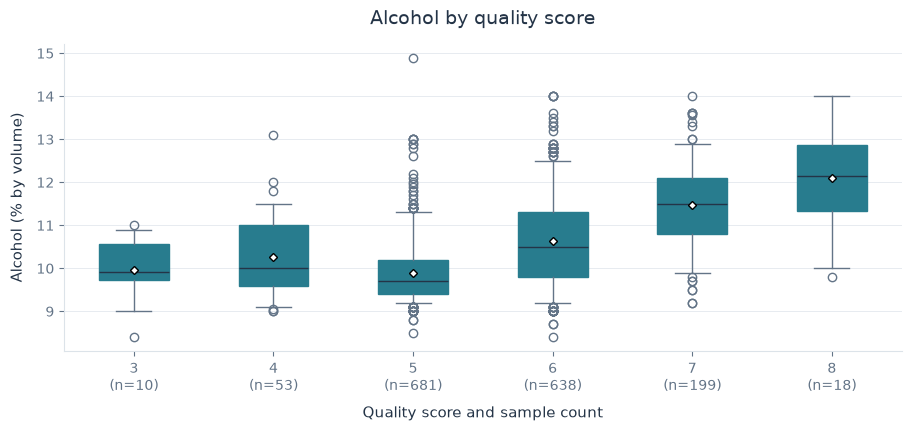

In [7]:
quality_levels = sorted(wines.df["quality"].unique())
alcohol_groups = [wines.df.loc[wines.df["quality"] == score, "alcohol"] for score in quality_levels]
box = Chart.box(
    alcohol_groups,
    tick_labels=[f"{score}\n(n={len(group)})" for score, group in zip(quality_levels, alcohol_groups)],
    whis=(5, 95), showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 4},
    title="Alcohol by quality score",
    xlabel="Quality score and sample count", ylabel="Alcohol (% by volume)",
    figsize=(9, 4.2),
)
box.show()

## Report: analysis pages and the complete data appendix

The report uses landscape A4 paper. All 1,599 observations and all 12 source columns are included, plus row numbers. The appendix explicitly slices the DataFrame into **32-row tables**, repeating headers and starting each section on a new page. Each table stays an intact block: this example manages row splitting itself; Report does not automatically paginate a single giant Table.

Fixed column proportions and compact typography keep the wide tables readable. Native table height follows its row count, avoiding excessive enlargement of the last section. The existing chart figures are reused after inline display.

In [8]:
report = Report("Red Wine Quality", figsize=(11.69, 8.27), margin=0.45)
report.add_text(
    "1,599 observations; 12 source columns. Red vinho verde wines from northern Portugal. "
    "Source: Cortez et al. (2009), UCI Wine Quality, DOI 10.24432/C56S3T; CC BY 4.0.",
    font_size=10, space_after=8,
)
report.add_table(summary_table)
report.add_text("Grouped means are descriptive summaries; associations do not establish causation.", font_size=10)
for chart, caption in (
    (scatter, "Each point represents one wine; color shows the recorded quality score."),
    (histogram, "Normalized distributions compare quality groups with different sample sizes."),
    (box, "Quality groups have different sample counts; whiskers use the 5th and 95th percentiles."),
):
    report.add_page_break().add_text(caption, font_size=10, space_after=8).add_chart(chart)

ROWS_PER_TABLE = 32
for start in range(0, len(display_data), ROWS_PER_TABLE):
    section = display_data.iloc[start:start + ROWS_PER_TABLE]
    stop = start + len(section)
    report.add_page_break().add_text(
        f"Data appendix: rows {start + 1}-{stop} of {len(display_data)}",
        font_size=12, font_weight="bold", space_after=6,
    )
    report.add_table(Table(
        section,
        style={"font_size": 8, "column_widths": [1] * len(section.columns)},
        figsize=(10.8, 0.7 + 0.165 * (len(section) + 2)),
    ))

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
report_path = output_dir / "wine_quality_report.pdf"
report.save(report_path)
for name, chart in (("scatter", scatter), ("histogram", histogram), ("box", box)):
    chart.save(output_dir / f"wine_quality_{name}.png", dpi=160)
print(f"Saved {report_path} with all {len(display_data):,} observations.")
print(f"Appendix tables: {(len(display_data) + ROWS_PER_TABLE - 1) // ROWS_PER_TABLE}")

Saved outputs/wine_quality_report.pdf with all 1,599 observations.
Appendix tables: 50
